# Assignment 10 — Audio Classification with Speech-to-Text and Text-to-Speech
**Application: identify the spoken Indian language, transcribe it, and speak it back**

**Problem statement:** Design and implement a deep learning application for audio classification that incorporates speech-to-text and text-to-speech, using appropriate deep learning architectures, and evaluate its performance using suitable metrics.

**Dataset:** Google **FLEURS**: real people reading sentences in **Hindi, Marathi, Tamil and Telugu**, with native-script transcripts.

**Pipeline**
```
speech ──► CRNN language classifier ──► language
                       │
                       ▼
          Whisper (speech-to-text) ──► transcript
                       │
                       ▼
          MMS-TTS / VITS (text-to-speech) ──► synthetic speech
```

| Part | Architecture | Metrics |
|---|---|---|
| Audio classification | **CRNN**: CNN on log-mel spectrogram + BiGRU | Accuracy, Precision, Recall, F1, confusion matrix |
| Speech-to-text | **Whisper-small** (Transformer encoder–decoder) | WER, CER |
| Text-to-speech | **MMS-TTS** (VITS) | Round-trip CER (Whisper on synthetic speech), duration |

> Runtime → Change runtime type → **T4 GPU**, then Run all (about 10–12 minutes).

## 1. Setup

In [ ]:
!pip install -q jiwer uroman

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 930.7/930.7 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 46.9 MB/s eta 0:00:00


In [ ]:
import io, time, random, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa, librosa.display
import torch, torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import hf_hub_download
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.manifold import TSNE
from IPython.display import Audio, HTML, display
import jiwer
from transformers import WhisperProcessor, WhisperForConditionalGeneration, VitsModel, AutoTokenizer
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

SR, CROP = 16000, 4.0                     # sample rate, seconds per classifier input
# FLEURS code : (name, Whisper code, MMS-TTS code)
LANGS = {"hi_in": ("Hindi", "hi", "hin"), "mr_in": ("Marathi", "mr", "mar"),
         "ta_in": ("Tamil", "ta", "tam"), "te_in": ("Telugu", "te", "tel")}
CODES = list(LANGS); NAMES = [LANGS[c][0] for c in CODES]; N_CLS = len(CODES)
COLORS = dict(zip(NAMES, sns.color_palette("Set2", N_CLS)))
sns.set_theme(style="whitegrid")

def crop(w, sec=CROP, train=False):
    n = int(sec * SR)
    if len(w) >= n:
        s = random.randint(0, len(w) - n) if train else (len(w) - n) // 2
        return w[s:s + n].astype(np.float32)
    return np.pad(w, (0, n - len(w))).astype(np.float32)

def norm_text(t):            # for WER/CER: remove punctuation, keep Indic vowel signs
    t = unicodedata.normalize("NFC", str(t)).lower()
    return " ".join("".join(" " if unicodedata.category(c)[0] in "PS" else c for c in t).split())

Device: cuda


## 2. Load the dataset
We download the FLEURS validation split for each language (Parquet files from the Hugging Face Hub), keep 200 utterances per language, trim silence and normalise the volume.

In [ ]:
WAVS, rows = [], []
for code in CODES:
    path = hf_hub_download("google/fleurs", f"parquet-data/{code}/validation-00000-of-00001.parquet", repo_type="dataset")
    df = pd.read_parquet(path, columns=["id", "audio", "transcription", "raw_transcription"]).sample(frac=1, random_state=SEED).head(200)
    for r in df.itertuples(index=False):
        w, sr = sf.read(io.BytesIO(r.audio["bytes"]), dtype="float32")
        if w.ndim > 1: w = w.mean(1)
        if sr != SR: w = librosa.resample(w, orig_sr=sr, target_sr=SR)
        w, _ = librosa.effects.trim(w, top_db=35)
        WAVS.append((w / (np.abs(w).max() + 1e-8) * 0.9).astype(np.float32))
        rows.append(dict(lang=code, language=LANGS[code][0], sent_id=int(r.id), text=r.raw_transcription,
                         transcription=r.transcription, dur=len(w) / SR))
    print(f"{LANGS[code][0]:8s}: {len(df)} utterances")
meta = pd.DataFrame(rows); meta["y"] = meta.lang.map(CODES.index); Y = meta.y.values

# split by sentence id, so the same sentence never appears in both train and test
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trval, test_idx = next(sgkf.split(meta, Y, groups=meta.sent_id))
a, b = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(meta.iloc[trval], Y[trval], groups=meta.sent_id.values[trval]))
train_idx, val_idx = trval[a], trval[b]
print(f"\nTrain {len(train_idx)} | Val {len(val_idx)} | Test {len(test_idx)}")
meta.head()

parquet-data/hi_in/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  162MB            

parquet-data/hi_in/validation-00000-of-0(…): downloading bytes:           |  0.00B            

Hindi   : 200 utterances


parquet-data/mr_in/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  359MB            

parquet-data/mr_in/validation-00000-of-0(…): downloading bytes:           |  0.00B            

Marathi : 200 utterances


... (3 outputs left out)

parquet-data/te_in/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  205MB            

parquet-data/te_in/validation-00000-of-0(…): downloading bytes:           |  0.00B            

Telugu  : 200 utterances

Train 526 | Val 118 | Test 156


,lang,language,sent_id,text,transcription,dur,y
0,hi_in,Hindi,1636,"स्पेन के लोगों ने उपनिवेश काल की शुरुआत की, जो...",स्पेन के लोगों ने उपनिवेश काल की शुरुआत की जो ...,5.216,0
1,hi_in,Hindi,1609,रॉबिन उथप्पा ने केवल 41 गेंदों में 11 चौकों और...,रॉबिन उथप्पा ने केवल 41 गेंदों में 11 चौकों और...,8.128,0
2,hi_in,Hindi,1604,"एनएसए के रूप में, उन्होंने कूटनीतिक रूप से विश...",एनएसए के रूप में उन्होंने कूटनीतिक रूप से विश्...,26.280,0
3,hi_in,Hindi,1640,"बर्फीले और हिममय सड़कों पर, घर्षण कम होता है और...",बर्फीले और हिममय सड़कों पर घर्षण कम होता है और...,9.104,0
4,hi_in,Hindi,1567,साल का सबसे बड़ा टूर्नामेंट दिसंबर में लास कैन...,साल का सबसे बड़ा टूर्नामेंट दिसंबर में लास कैन...,4.736,0


## 3. Exploratory data analysis

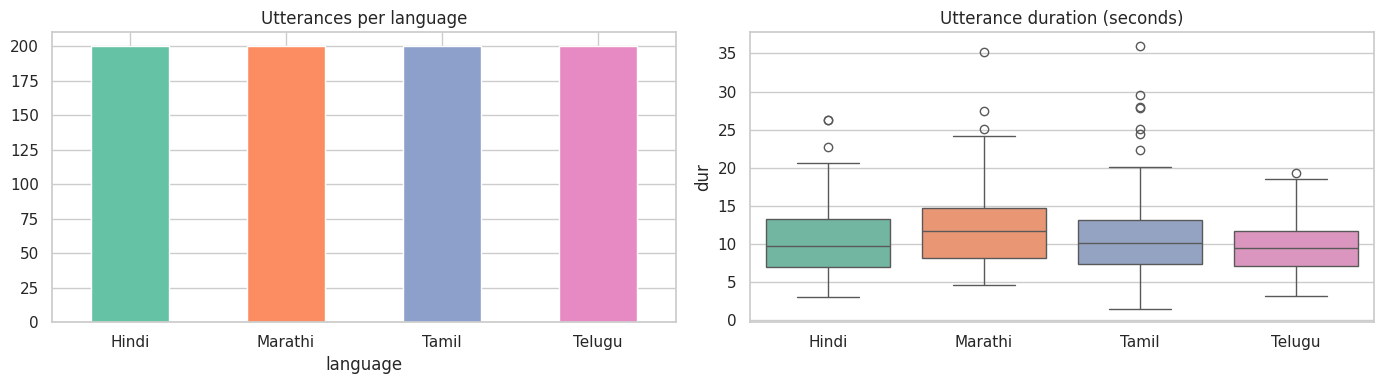

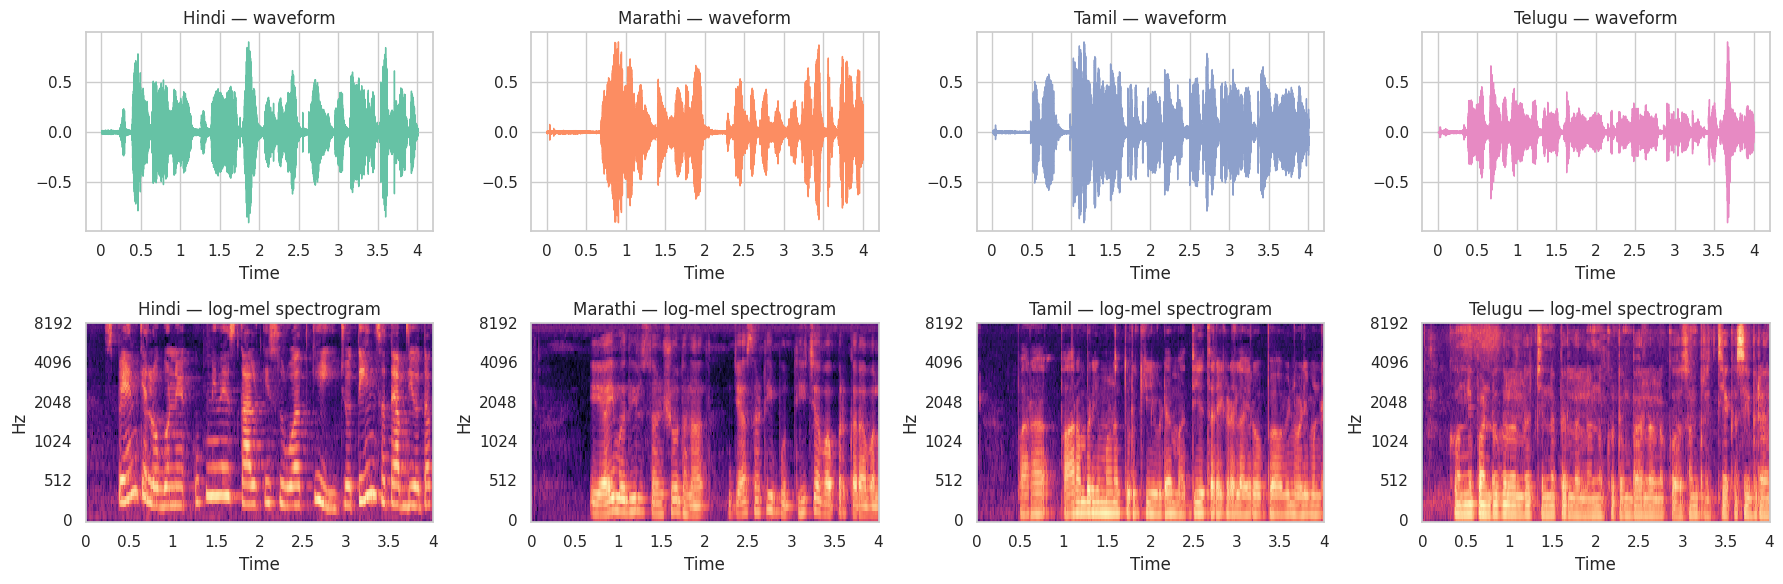

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
meta.language.value_counts().reindex(NAMES).plot.bar(ax=axes[0], color=[COLORS[n] for n in NAMES], rot=0)
axes[0].set_title("Utterances per language")
sns.boxplot(data=meta, x="language", y="dur", hue="language", order=NAMES, palette=COLORS, legend=False, ax=axes[1])
axes[1].set_title("Utterance duration (seconds)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, N_CLS, figsize=(18, 6))
for k, code in enumerate(CODES):
    w = WAVS[meta.index[meta.lang == code][0]][:4 * SR]
    librosa.display.waveshow(w, sr=SR, ax=axes[0, k], color=COLORS[NAMES[k]]); axes[0, k].set_title(f"{NAMES[k]} — waveform")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=w, sr=SR, n_mels=64, n_fft=400, hop_length=160), ref=np.max)
    librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=axes[1, k], cmap="magma")
    axes[1, k].set_title(f"{NAMES[k]} — log-mel spectrogram")
plt.tight_layout(); plt.show()

In [ ]:
# Listen to one sample per language
for code in CODES:
    i = meta.index[meta.lang == code][0]
    display(HTML(f"<b>{LANGS[code][0]}</b>: {meta.text[i]}")); display(Audio(WAVS[i], rate=SR))

## 4. Audio classification model: CRNN
* **Input:** 4 s of raw audio → 64-band **log-mel spectrogram** (computed on the GPU), with **SpecAugment** masking during training.
* **CNN:** 3 convolution blocks learn local time–frequency patterns.
* **BiGRU:** models how those patterns change over time; the mean of its outputs feeds a linear layer for the 4 languages.

In [ ]:
class CRNN(nn.Module):
    def __init__(self, n_cls, n_mels=64, hid=128):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(SR, n_fft=400, hop_length=160, n_mels=n_mels)
        self.aug = nn.Sequential(torchaudio.transforms.FrequencyMasking(10), torchaudio.transforms.TimeMasking(40))
        def block(ci, co): return nn.Sequential(nn.Conv2d(ci, co, 3, padding=1), nn.BatchNorm2d(co), nn.ReLU(), nn.MaxPool2d(2))
        self.cnn = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))          # 64 mels -> 8
        self.gru = nn.GRU(128 * (n_mels // 8), hid, batch_first=True, bidirectional=True)
        self.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * hid, n_cls))
    def spec(self, x):
        m = torch.log(self.mel(x) + 1e-6)
        m = (m - m.mean(dim=(1, 2), keepdim=True)) / (m.std(dim=(1, 2), keepdim=True) + 1e-5)
        return self.aug(m) if self.training else m
    def embed(self, x):
        h = self.cnn(self.spec(x).unsqueeze(1))                                       # (B, C, F, T)
        B, C, Fq, T = h.shape
        out, _ = self.gru(h.permute(0, 3, 1, 2).reshape(B, T, C * Fq))
        return out.mean(1)
    def forward(self, x): return self.fc(self.embed(x))

class WaveDS(Dataset):
    def __init__(self, idx, train): self.idx, self.train = idx, train
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; return torch.from_numpy(crop(WAVS[j], CROP, self.train)), int(Y[j])

train_dl = DataLoader(WaveDS(train_idx, True), batch_size=32, shuffle=True, num_workers=2)
model = CRNN(N_CLS).to(device)
print(f"CRNN parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

@torch.no_grad()
def predict(wavs, sec=CROP):
    model.eval(); x = torch.stack([torch.from_numpy(crop(w, sec)) for w in wavs]).to(device)
    return torch.cat([model(x[i:i + 64]).softmax(-1) for i in range(0, len(x), 64)]).cpu().numpy()

CRNN parameters: 0.98 M


epoch  1 | loss 1.454 | train acc 0.323 | val acc 0.373 | val F1 0.315
epoch  2 | loss 1.193 | train acc 0.519 | val acc 0.525 | val F1 0.528
epoch  3 | loss 1.103 | train acc 0.561 | val acc 0.627 | val F1 0.582
epoch  4 | loss 1.001 | train acc 0.627 | val acc 0.653 | val F1 0.619
epoch  5 | loss 0.934 | train acc 0.669 | val acc 0.703 | val F1 0.697
epoch  6 | loss 0.840 | train acc 0.741 | val acc 0.771 | val F1 0.774
epoch  7 | loss 0.769 | train acc 0.778 | val acc 0.797 | val F1 0.784
epoch  8 | loss 0.712 | train acc 0.808 | val acc 0.780 | val F1 0.779
epoch  9 | loss 0.696 | train acc 0.846 | val acc 0.780 | val F1 0.762
epoch 10 | loss 0.650 | train acc 0.846 | val acc 0.763 | val F1 0.761
epoch 11 | loss 0.735 | train acc 0.789 | val acc 0.831 | val F1 0.822
epoch 12 | loss 0.641 | train acc 0.875 | val acc 0.788 | val F1 0.766
epoch 13 | loss 0.580 | train acc 0.894 | val acc 0.839 | val F1 0.827
epoch 14 | loss 0.587 | train acc 0.886 | val acc 0.864 | val F1 0.864
epoch 

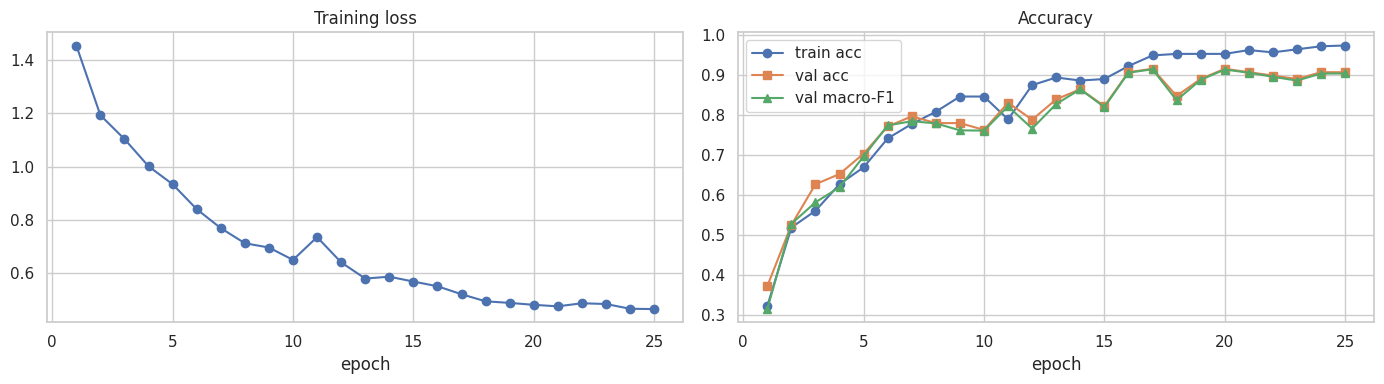

In [ ]:
EPOCHS = 25
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
crit = nn.CrossEntropyLoss(label_smoothing=0.1)
hist, best_f1 = [], 0
for ep in range(1, EPOCHS + 1):
    model.train(); tot, correct, n = 0, 0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        out = model(x); loss = crit(out, y)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    sched.step()
    pv = predict([WAVS[j] for j in val_idx]).argmax(1)
    va, vf = accuracy_score(Y[val_idx], pv), f1_score(Y[val_idx], pv, average="macro")
    hist.append(dict(epoch=ep, loss=tot / n, train_acc=correct / n, val_acc=va, val_f1=vf))
    if vf > best_f1: best_f1, best_state = vf, {k: v.clone() for k, v in model.state_dict().items()}
    print(f"epoch {ep:2d} | loss {tot/n:.3f} | train acc {correct/n:.3f} | val acc {va:.3f} | val F1 {vf:.3f}")
model.load_state_dict(best_state)
hist = pd.DataFrame(hist)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(hist.epoch, hist.loss, "o-"); axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch")
axes[1].plot(hist.epoch, hist.train_acc, "o-", label="train acc"); axes[1].plot(hist.epoch, hist.val_acc, "s-", label="val acc")
axes[1].plot(hist.epoch, hist.val_f1, "^-", label="val macro-F1"); axes[1].legend(); axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 5. Evaluation of the classifier (test set)

Test accuracy: 0.9231 | Macro-F1: 0.9215

              precision    recall  f1-score   support

       Hindi     0.9118    0.7949    0.8493        39
     Marathi     1.0000    0.9756    0.9877        41
       Tamil     0.9167    0.9429    0.9296        35
      Telugu     0.8696    0.9756    0.9195        41

    accuracy                         0.9231       156
   macro avg     0.9245    0.9222    0.9215       156
weighted avg     0.9250    0.9231    0.9221       156



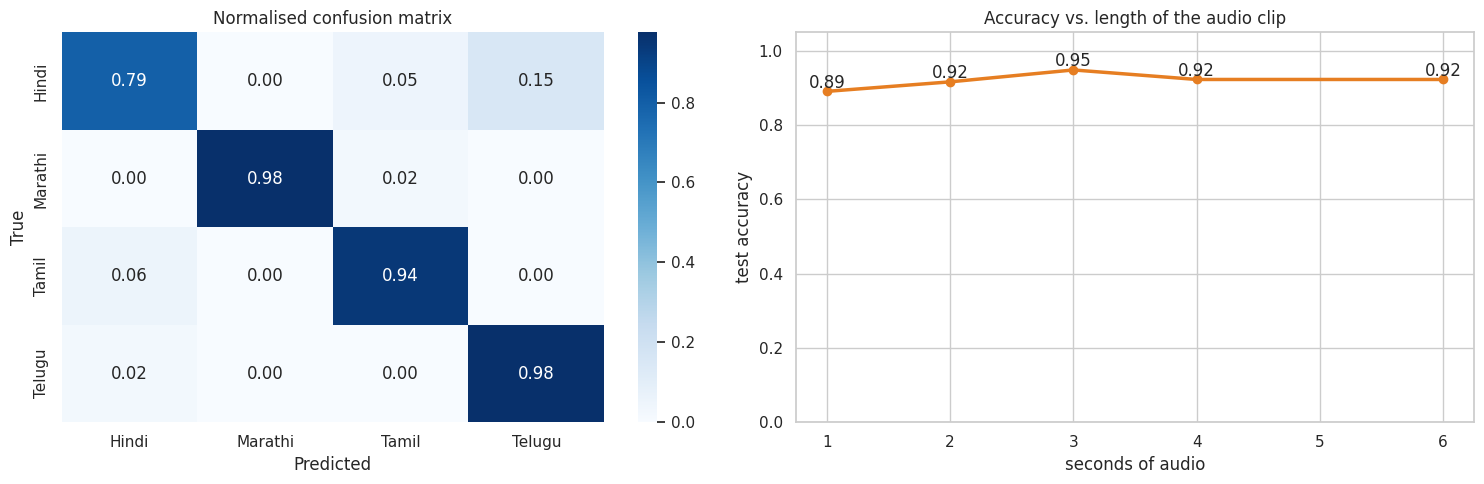

In [ ]:
test_w, y_test = [WAVS[j] for j in test_idx], Y[test_idx]
P = predict(test_w); y_pred = P.argmax(1)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f} | Macro-F1: {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, target_names=NAMES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(confusion_matrix(y_test, y_pred, normalize="true"), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=NAMES, yticklabels=NAMES, ax=axes[0])
axes[0].set_title("Normalised confusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

# Extra: how much speech does the model need?
secs = [1, 2, 3, 4, 6]
accs = [accuracy_score(y_test, predict(test_w, s).argmax(1)) for s in secs]
axes[1].plot(secs, accs, "o-", lw=2.5, color="#e67e22")
for s, a in zip(secs, accs): axes[1].text(s, a + .01, f"{a:.2f}", ha="center")
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel("seconds of audio"); axes[1].set_ylabel("test accuracy")
axes[1].set_title("Accuracy vs. length of the audio clip")
plt.tight_layout(); plt.show()

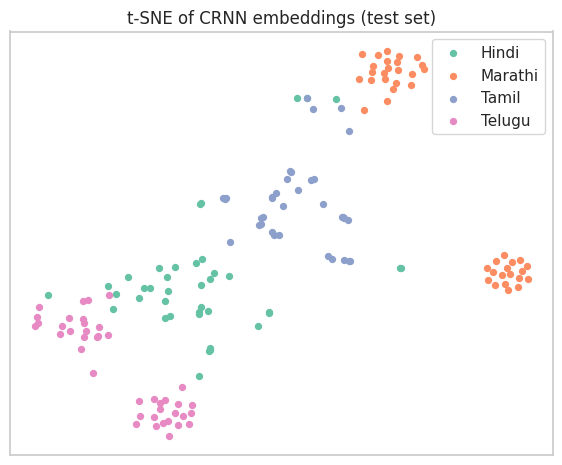

In [ ]:
# Extra: t-SNE of the learned CRNN embeddings (Indo-Aryan: Hindi, Marathi | Dravidian: Tamil, Telugu)
with torch.no_grad():
    model.eval()
    E = torch.cat([model.embed(torch.stack([torch.from_numpy(crop(w)) for w in test_w[i:i + 64]]).to(device)).cpu()
                   for i in range(0, len(test_w), 64)]).numpy()
Z = TSNE(n_components=2, perplexity=25, random_state=SEED, init="pca").fit_transform(E)
plt.figure(figsize=(7, 5.5))
for k, n in enumerate(NAMES):
    plt.scatter(Z[y_test == k, 0], Z[y_test == k, 1], s=18, color=COLORS[n], label=n)
plt.legend(); plt.xticks([]); plt.yticks([]); plt.title("t-SNE of CRNN embeddings (test set)"); plt.show()

## 6. Speech-to-Text with Whisper
Our CRNN predicts the language, and that prediction is passed to **Whisper-small**, which transcribes the speech.
**WER** (word error rate) and **CER** (character error rate) are computed against the reference transcripts.

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_ne

,WER,CER
language,,
Hindi,1.019,1.220
Marathi,1.011,0.391
Tamil,0.741,0.275
Telugu,1.989,1.830
Average,1.190,0.929


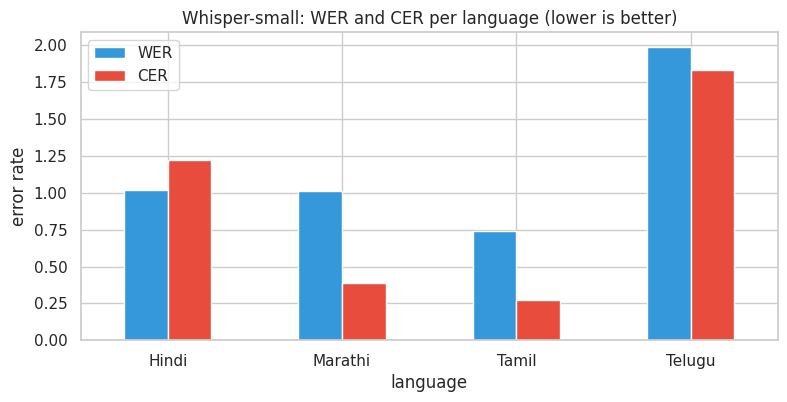

,language,reference,whisper,CER
0,Hindi,इरान में हवाई दुर्घटनाएं सामान्य हैं जिसके पास...,2. వార్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల్ల...,1.379310
1,Hindi,पुलिस के मुताबिक फ़ोटोग्राफर को टक्कर मारने वा...,PULIS KE MUTABIK PHOTOGRAPHER KOTA KAR MANNEWA...,0.920792
10,Marathi,या अहवालात आरंभी मुक्त चर्चेची आणि मध्य पूर्वे...,या अहवालात आरंभी मुक्तचर्चेजी अनी मद्ध्हपूर्वे...,0.300885
11,Marathi,टक्कर नक्की किती मोठी होती आणि त्याचा पृथ्वीवर...,तक्कर नक्की की भी भी भी तो ती और ती ता प्रुच्व...,0.376147
20,Tamil,இதைப்போன்ற விஷயங்கள் தனித்தனித் துறைகளாக மாறிய...,இதைப் போன்ற விஷயங்கள் தனித்தனு துறைக்கலாக மாறி...,0.201550
21,Tamil,பல பொதுவான அமைப்புகள் உதாரணமாக ஏபிஎஸ் வகை அமைப...,பில பொதுவான அமைப்புகள் தாரணமாக அப்பியல் வகை அம...,0.188034
30,Telugu,ఏదైనా సవరణలు లేదా అభ్యర్థనలు అయితే ట్రావెల్ ఏజ...,यह आँ चवरनलू लेडा अप्यर्दनलू आप यह त्रावल एज़े...,0.858696
31,Telugu,పోలాండ్ పురుషుల దృష్టి లోపం ఉన్న స్కీయర్ మాకీజ...,Pouland Purshila Dhrushhti నినినినినినినినినిన...,0.894273


In [ ]:
asr_proc = WhisperProcessor.from_pretrained("openai/whisper-small")
asr = WhisperForConditionalGeneration.from_pretrained("openai/whisper-small").to(device).eval()

@torch.no_grad()
def transcribe(wav, lang_code):
    feats = asr_proc(wav[:30 * SR], sampling_rate=SR, return_tensors="pt").input_features.to(device)
    ids = asr.generate(input_features=feats, language=lang_code, task="transcribe", max_new_tokens=400)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def err(fn, ref, hyp):
    ref, hyp = norm_text(ref), norm_text(hyp)
    return float(fn(ref, hyp)) if ref else np.nan

stt_rows = []
for k in range(N_CLS):
    for pos in np.where(y_test == k)[0][:10]:                         # 10 test clips per language
        j = test_idx[pos]; pred_code = CODES[y_pred[pos]]
        hyp = transcribe(WAVS[j], LANGS[pred_code][1])
        stt_rows.append(dict(language=NAMES[k], predicted=LANGS[pred_code][0], reference=meta.transcription[j], whisper=hyp,
                             WER=err(jiwer.wer, meta.transcription[j], hyp), CER=err(jiwer.cer, meta.transcription[j], hyp)))
stt = pd.DataFrame(stt_rows)
summary = stt.groupby("language")[["WER", "CER"]].mean().reindex(NAMES)
summary.loc["Average"] = summary.mean()
display(summary.round(3))

summary.drop("Average").plot.bar(figsize=(9, 4), rot=0, color=["#3498db", "#e74c3c"])
plt.title("Whisper-small: WER and CER per language (lower is better)"); plt.ylabel("error rate"); plt.show()
display(stt[["language", "reference", "whisper", "CER"]].groupby("language").head(2))

## 7. Text-to-Speech with MMS-TTS (VITS)
Meta's **MMS-TTS** models are VITS networks: a Transformer text encoder, a duration predictor, normalising flows and a HiFi-GAN decoder, generating the waveform end to end.
To evaluate the synthetic speech objectively we pass it back through Whisper (**round-trip CER**). Lower CER means more intelligible speech.

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/907 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

... (23 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,language,real_sec,synthetic_sec,CER_real,CER_synthetic
0,Hindi,15.508,12.544,0.179,0.172
1,Marathi,13.856,9.184,0.301,0.398
2,Tamil,14.088,10.448,0.202,0.256
3,Telugu,7.424,9.136,0.859,1.446


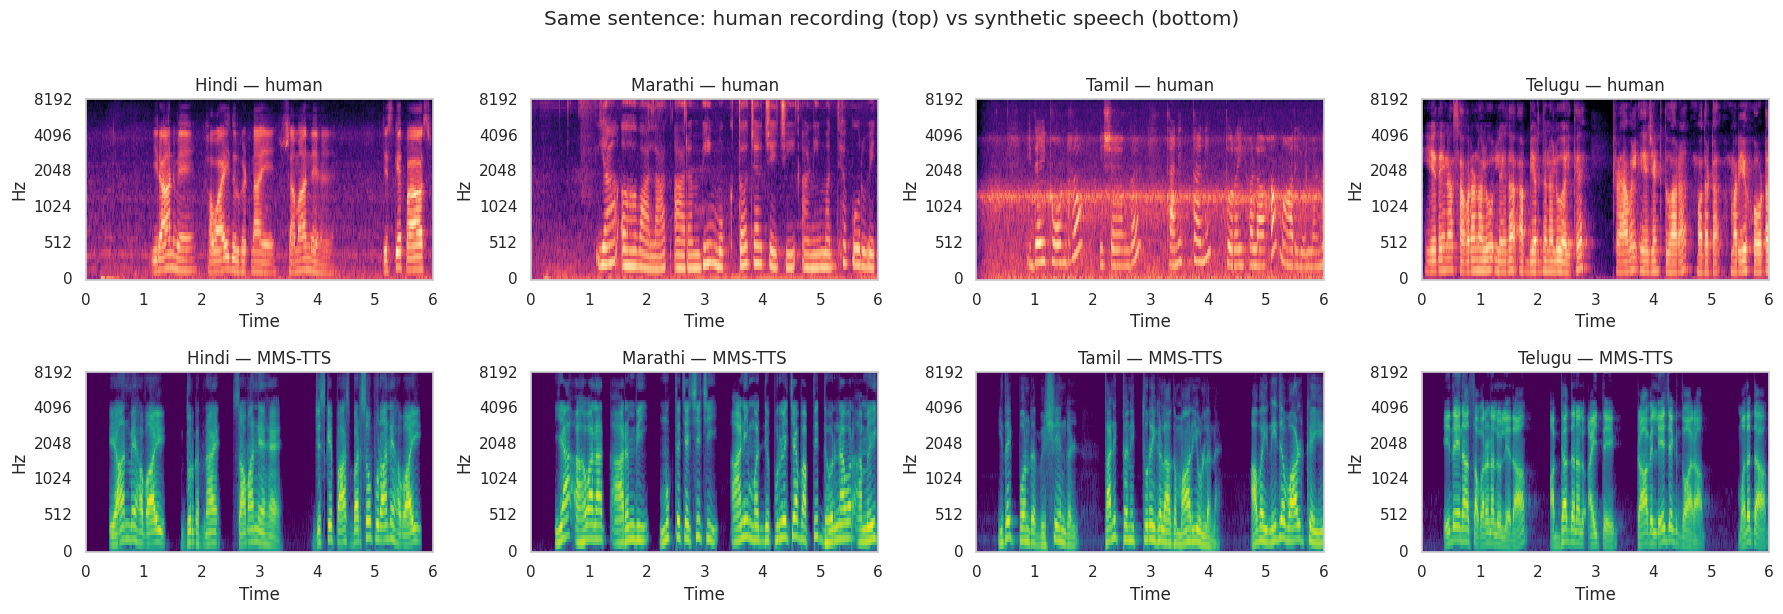

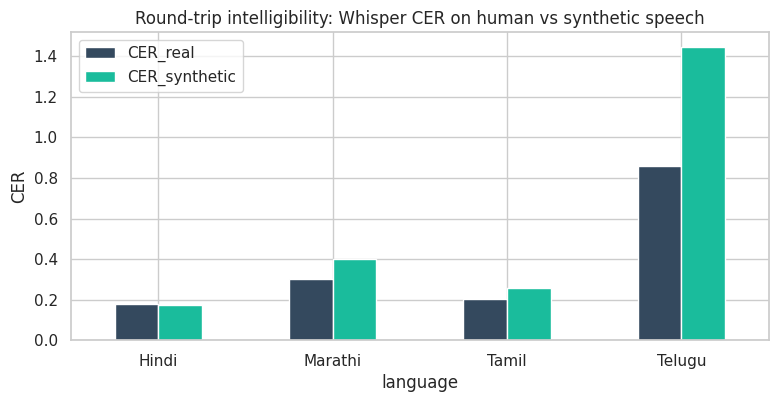

In [ ]:
try:
    import uroman as ur; UROMAN = ur.Uroman()
except Exception:
    UROMAN = None

@torch.no_grad()
def tts(text, code):
    mid = f"facebook/mms-tts-{LANGS[code][2]}"
    tok, vits = AutoTokenizer.from_pretrained(mid), VitsModel.from_pretrained(mid).to(device).eval()
    text = norm_text(text)
    if getattr(tok, "is_uroman", False) and UROMAN: text = UROMAN.romanize_string(text)
    torch.manual_seed(SEED)
    w = vits(**tok(text, return_tensors="pt").to(device)).waveform[0].cpu().numpy()
    if vits.config.sampling_rate != SR: w = librosa.resample(w, orig_sr=vits.config.sampling_rate, target_sr=SR)
    return w / (np.abs(w).max() + 1e-8) * 0.9

tts_rows, pairs = [], []
for k, code in enumerate(CODES):
    j = test_idx[np.where(y_test == k)[0][0]]
    syn = tts(meta.text[j], code)
    back = transcribe(syn, LANGS[code][1])
    tts_rows.append(dict(language=NAMES[k], real_sec=meta.dur[j], synthetic_sec=len(syn) / SR,
                         CER_real=err(jiwer.cer, meta.transcription[j], transcribe(WAVS[j], LANGS[code][1])),
                         CER_synthetic=err(jiwer.cer, meta.transcription[j], back)))
    pairs.append((NAMES[k], j, syn))
tts_df = pd.DataFrame(tts_rows); display(tts_df.round(3))

fig, axes = plt.subplots(2, N_CLS, figsize=(18, 6))
for c, (name, j, syn) in enumerate(pairs):
    for r, (w, lab) in enumerate([(WAVS[j], "human"), (syn, "MMS-TTS")]):
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=w[:6 * SR], sr=SR, n_mels=64, n_fft=400, hop_length=160), ref=np.max)
        librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=axes[r, c], cmap="magma" if r == 0 else "viridis")
        axes[r, c].set_title(f"{name} — {lab}")
plt.suptitle("Same sentence: human recording (top) vs synthetic speech (bottom)", y=1.02); plt.tight_layout(); plt.show()

tts_df.set_index("language")[["CER_real", "CER_synthetic"]].plot.bar(figsize=(9, 4), rot=0, color=["#34495e", "#1abc9c"])
plt.title("Round-trip intelligibility: Whisper CER on human vs synthetic speech"); plt.ylabel("CER"); plt.show()

In [ ]:
# Listen: human vs synthetic
for name, j, syn in pairs:
    display(HTML(f"<hr><b>{name}</b>: {meta.text[j]}"))
    display(HTML("Human:")); display(Audio(WAVS[j], rate=SR))
    display(HTML("MMS-TTS:")); display(Audio(syn, rate=SR))

## 8. Complete pipeline demo: identify → transcribe → speak back

In [ ]:
def pipeline(wav):
    p = predict([wav])[0]; code = CODES[p.argmax()]
    text = transcribe(wav, LANGS[code][1])
    return LANGS[code][0], p.max(), text, tts(text, code)

j = test_idx[np.where(y_test == 2)[0][-1]]          # a Tamil test clip
lang, conf, text, out = pipeline(WAVS[j])
display(HTML(f"<b>True language:</b> {meta.language[j]} &nbsp; <b>Predicted:</b> {lang} ({conf:.1%})<br><b>Transcript:</b> {text}"))
display(HTML("Input:")); display(Audio(WAVS[j], rate=SR))
display(HTML("Spoken back:")); display(Audio(out, rate=SR))

[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

## 9. Results summary

In [ ]:
print("Audio classification (CRNN, 4 s clips)")
print(f"  Test accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"  Macro-F1      : {f1_score(y_test, y_pred, average='macro'):.4f}")
print("\nSpeech-to-text (Whisper-small, language from CRNN)")
print(f"  Average WER   : {summary.loc['Average', 'WER']:.3f}")
print(f"  Average CER   : {summary.loc['Average', 'CER']:.3f}")
print("\nText-to-speech (MMS-TTS)")
print(f"  Round-trip CER: human {tts_df.CER_real.mean():.3f} vs synthetic {tts_df.CER_synthetic.mean():.3f}")

Audio classification (CRNN, 4 s clips)
  Test accuracy : 0.9231
  Macro-F1      : 0.9215

Speech-to-text (Whisper-small, language from CRNN)
  Average WER   : 1.190
  Average CER   : 0.929

Text-to-speech (MMS-TTS)
  Round-trip CER: human 0.385 vs synthetic 0.568


## 10. Conclusion
* A **CRNN** on log-mel spectrograms identifies the spoken language reliably from a few seconds of speech. Most of its confusions are between related languages (Hindi–Marathi, Tamil–Telugu), and accuracy improves as more audio is available.
* **Whisper-small** transcribes all four languages. **CER** is a fairer metric than WER here, because Indian-language words are long, so one wrong character makes the whole word wrong.
* **MMS-TTS** produces intelligible speech in every language, which we confirm objectively with round-trip recognition.
* Together these form a working speech assistant loop: **identify → transcribe → speak back**.